In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../wildfire-dataset")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 04. Plants and land cover (NDVI and WorldCover)

Two different kinds of information:

- **NDVI** changes through the year: how green and alive the plants are (MODIS satellite, 1 km, a new value every 16 days).
- **WorldCover** is a fixed map of what covers the ground (ESA, 10 m, the year 2021 only).

Dry, brown grass burns more easily than green leaves, so NDVI is a clue about fuel dryness. Land cover tells what kind of area it is.

## 1. NDVI: raw files

In [2]:
SOURCES = {"newer states": RAW + "/gee_new_states", "first six states": RAW + "/gee_six_states"}     # same file format in both
nd = pd.concat(pd.read_csv(f).assign(source=k) for k, p in SOURCES.items() for f in sorted(glob.glob(p + "/ndvi/*.csv")))
nd["comp_start"] = pd.to_datetime(nd.comp_start)
print(len(nd), "rows.  one row = one cell and one 16-day composite")
print(nd.groupby("source").agg(rows=("ndvi", "size"), cells=("cell_id", "nunique"), first=("comp_start", "min"), last=("comp_start", "max")))
nd.head(4)

2064526 rows.  one row = one cell and one 16-day composite
                     rows  cells      first       last
source                                                
first six states   439806   9561 2021-01-01 2022-12-19
newer states      1624720   8830 2018-01-01 2025-12-19


,cell_id,lon,lat,comp_start,ndvi,valid_frac,source
0,81775,77.5,8.1,2018-01-01,0.647118,1.0,newer states
1,82773,77.3,8.2,2018-01-01,0.694054,1.0,newer states
2,82774,77.4,8.2,2018-01-01,0.645689,1.0,newer states
3,82775,77.5,8.2,2018-01-01,0.629149,1.0,newer states


Both batches (the first six states and the newer states) have the same columns. All of them are in our cloud bucket; on this disk we have all years for the newer states and 2021 to 2022 for the first six, which is enough to show the method.

`comp_start` is the first day of a 16-day composite. `ndvi` goes from -1 to 1 (more than 0.5 is dense green plants).
`valid_frac` says how much of the cell had clear, usable pixels. Empty values mean clouds hid the whole cell.

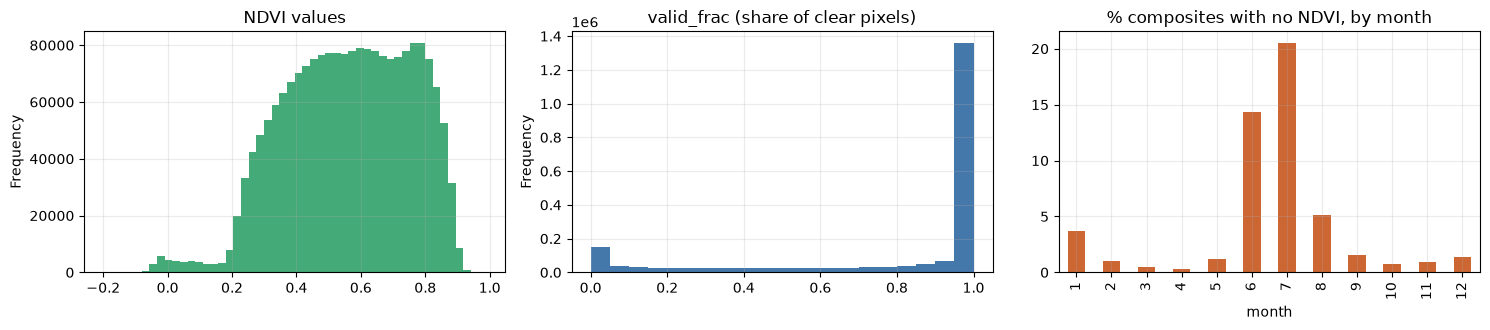

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
nd.ndvi.plot.hist(bins=50, ax=ax[0], color="#4a7"); ax[0].set_title("NDVI values")
nd.valid_frac.plot.hist(bins=20, ax=ax[1], color="#47a"); ax[1].set_title("valid_frac (share of clear pixels)")
nd.groupby(nd.comp_start.dt.month).ndvi.apply(lambda s: s.isna().mean() * 100).plot.bar(ax=ax[2], color="#c63"); ax[2].set_title("% composites with no NDVI, by month"); ax[2].set_xlabel("month")
plt.tight_layout(); plt.show()

In the monsoon months (June to September) many composites are empty because of clouds.

## 2. From 16-day composites to one value per day

The model needs a number for **every day**. Our rule, in plain words:

1. A composite is available from the **last day of its 16 days** (we do not peek into the future).
2. Each day we use the **newest composite that has a value**.
3. We also store how old that value is, as `ndvi_age_days`. The model can learn to trust old values less.

first six states -> chosen cell: 157741 MH
newer states -> chosen cell: 83774 Tamil Nadu


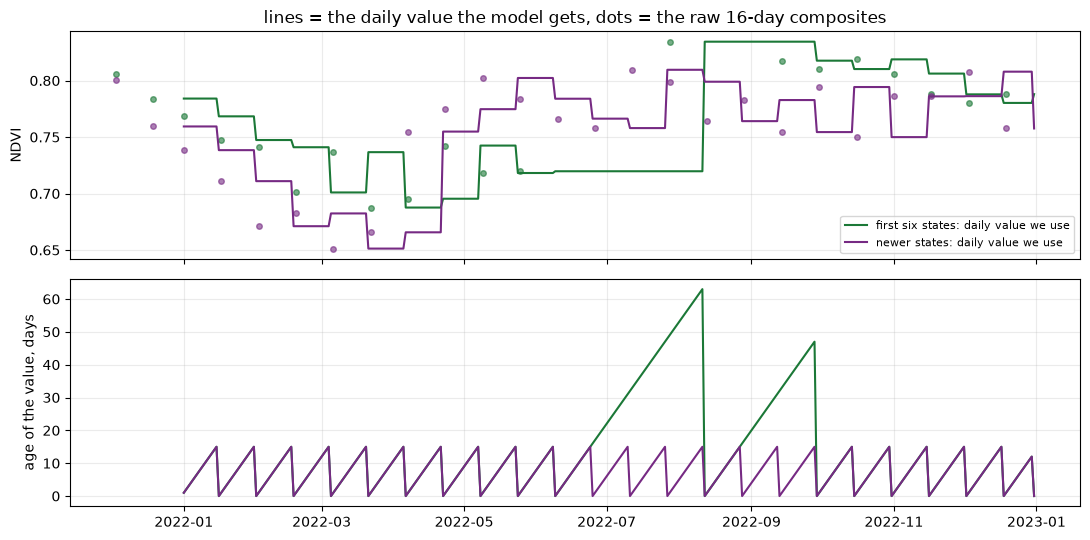

In [4]:
cells = pd.read_parquet(f"{DS}/forest_all/cells.parquet")
days = pd.date_range("2022-01-01", "2022-12-31")

def ndvi_daily(cell_id):
    "daily NDVI and its age for one cell: the newest composite that has ended and has a value"
    one = nd[nd.cell_id == cell_id].sort_values("comp_start")
    one = one[(one.comp_start >= "2021-12-01") & (one.comp_start <= "2022-12-31")]
    ends = [min(s_ + pd.Timedelta(days=15), pd.Timestamp(year=s_.year, month=12, day=31)) for s_ in one.comp_start]     # last day of each composite
    val, age = [], []
    for dday in days:
        best = None
        for e, v in zip(ends, one.ndvi):
            if e <= dday and not np.isnan(v): best = (e, v)
        val.append(best[1] if best else np.nan); age.append((dday - best[0]).days if best else np.nan)
    return np.array(val), np.array(age), one

picked = {}
for label, group in [("first six states", "six"), ("newer states", "south")]:
    picked[label] = cells[(cells.set == group) & cells.cell_id.isin(nd[nd.source == label].cell_id.unique())].iloc[0]
    print(label, "-> chosen cell:", int(picked[label].cell_id), picked[label].state)

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
daily = {}
for (label, r), col in zip(picked.items(), ["#1b7837", "#762a83"]):
    val, age, one = ndvi_daily(r.cell_id); daily[label] = (val, age)
    ax[0].plot(days, val, color=col, label=label + ": daily value we use"); ax[0].plot(one.comp_start, one.ndvi, "o", ms=4, color=col, alpha=0.6)
    ax[1].plot(days, age, color=col, label=label)
ax[0].set_ylabel("NDVI"); ax[0].legend(fontsize=8); ax[1].set_ylabel("age of the value, days"); ax[0].set_title("lines = the daily value the model gets, dots = the raw 16-day composites")
plt.tight_layout(); plt.show()

In [5]:
# compare with the numbers stored in the cube for the same cells
import sys; sys.path.insert(0, os.path.abspath("../src"))
from wildfire_forecast import data
ds = data.load_train(); names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]
tt = (days - START).days.values
for label, r in picked.items():
    val, age = daily[label]
    stored_v = np.asarray(ds.cube[tt, int(r.cell_idx), names.index("ndvi")]); stored_a = np.asarray(ds.cube[tt, int(r.cell_idx), names.index("ndvi_age_days")])
    print(f"{label:17s} largest difference, ndvi: {np.nanmax(np.abs(val - stored_v)):.1e}   ndvi_age_days: {np.nanmax(np.abs(age - stored_a)):.0f}")

first six states  largest difference, ndvi: 2.9e-08   ndvi_age_days: 0
newer states      largest difference, ndvi: 3.0e-08   ndvi_age_days: 0


## 3. Land cover: raw files

WorldCover is a map in 10 m pixels. We turned it into **shares per 0.1 degree cell** (for example 43% tree, 4% shrub) through Earth Engine. The CSV below is that table.

In [6]:
wc = pd.concat(pd.read_csv(f).assign(source=k) for k, p in SOURCES.items() for f in sorted(glob.glob(p + "/worldcover/*.csv")))
print(len(wc), "cells in the raw table:", wc.source.value_counts().to_dict())
wc.head(4).round(3)

18391 cells in the raw table: {'first six states': 9561, 'newer states': 8830}


,cell_id,lon,lat,wc_tree,wc_shrub,wc_grass,wc_crop,wc_built,wc_bare,wc_snow,wc_water,wc_wetland,wc_mangrove,wc_moss,source
0,81775,77.5,8.1,0.430,0.005,0.038,0.065,0.052,0.007,0.0,0.386,0.013,0.004,0.0,newer states
1,82773,77.3,8.2,0.853,0.000,0.006,0.021,0.052,0.003,0.0,0.064,0.001,0.000,0.0,newer states
2,82774,77.4,8.2,0.619,0.001,0.057,0.165,0.151,0.003,0.0,0.003,0.002,0.000,0.0,newer states
3,82775,77.5,8.2,0.647,0.040,0.049,0.192,0.053,0.005,0.0,0.004,0.009,0.000,0.0,newer states


ESA_WorldCover_10m_2021_v200_N06E075_Map.tif
size 36000 x 36000 pixels, 9.2 m per pixel, crs EPSG:4326
what is in this 12 km x 12 km piece:
{'tree': 93.7, 'grass': 6.2, 'water': 0.2, 'bare': 0.0, 'crop': 0.0, 'shrub': 0.0}


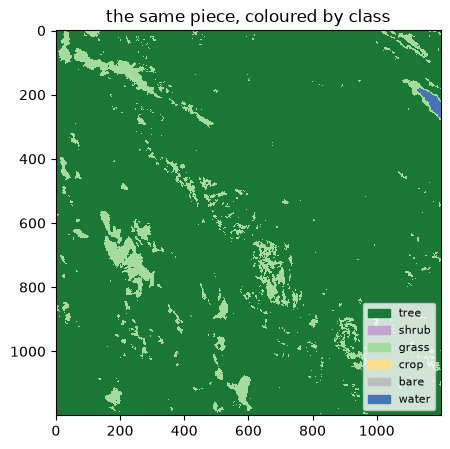

In [7]:
# one WorldCover tile as it comes from ESA: a GeoTIFF with one class code per 10 m pixel
import rasterio
tile = sorted(glob.glob(V4 + "/_tiles/*.tif"))[0]
with rasterio.open(tile) as r:
    print(os.path.basename(tile)); print("size", r.width, "x", r.height, "pixels,", round(r.res[0] * 111000, 1), "m per pixel, crs", r.crs)
    coarse = r.read(1, out_shape=(r.height // 30, r.width // 30))              # a small overview, to find a spot with trees
    ys, xs = np.where(coarse == 10); k = len(ys) // 2
    y0, x0 = max(ys[k] * 30 - 600, 0), max(xs[k] * 30 - 600, 0)
    piece = r.read(1, window=rasterio.windows.Window(x0, y0, 1200, 1200))
classes = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built-up", 60: "bare", 80: "water", 90: "wetland", 95: "mangrove"}
print("what is in this 12 km x 12 km piece:"); print((pd.Series(piece.ravel()).map(classes).value_counts(normalize=True) * 100).round(1).to_dict())
colors = {10: "#1b7837", 20: "#c2a5cf", 30: "#a6dba0", 40: "#fee08b", 50: "#d73027", 60: "#bdbdbd", 80: "#4575b4", 90: "#9ecae1", 95: "#66c2a4"}
rgb = np.ones(piece.shape + (3,))
for code_, hexcol in colors.items(): rgb[piece == code_] = [int(hexcol[i:i + 2], 16) / 255 for i in (1, 3, 5)]
plt.figure(figsize=(5, 5)); plt.imshow(rgb, interpolation="nearest"); plt.grid(False); plt.title("the same piece, coloured by class")
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[k], label=classes[k]) for k in colors if k in np.unique(piece)], fontsize=8, loc="lower right"); plt.show()

In the cube, four shares are used: `forest_fraction` (tree), `shrub_fraction`, `grass_fraction`, `crop_fraction`.

**Do not mix up two "forest" numbers in the cube:**

- `forest_fraction` is **tree cover** from WorldCover (what the satellite sees as trees).
- `forest_land_frac` (channel 27) is **legal forest land** from the boundary maps (notebook 02). This is the one that defines our cells.

They agree only partly (see the correlation below): open forest land has few trees, and a plantation or a garden has many trees but is not forest land.

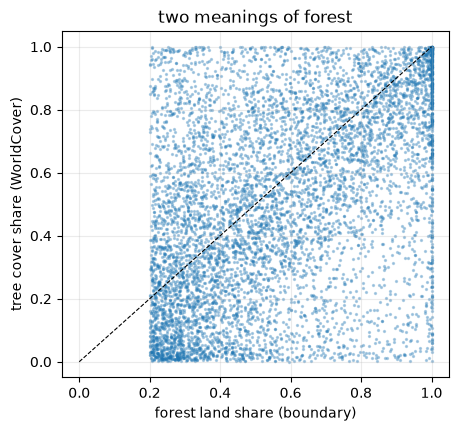

correlation: 0.45


In [8]:
cube_cells = cells.copy()
# tree cover vs legal forest land for the training cells (tree cover is static in the cube, so take one day)
stat = np.asarray(ds.cube[1000][:, [names.index("forest_fraction"), names.index("forest_land_frac")]])
plt.figure(figsize=(5, 4.5)); plt.scatter(stat[:, 1], stat[:, 0], s=2, alpha=0.3); plt.xlabel("forest land share (boundary)"); plt.ylabel("tree cover share (WorldCover)"); plt.title("two meanings of forest")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.show()
print("correlation:", round(float(np.corrcoef(stat[:, 0], stat[:, 1])[0, 1]), 2))

In [9]:
# do the raw land-cover shares equal the cube values, for ALL forest cells of both batches together?
both = cells.merge(wc, on="cell_id")
cube_shares = np.asarray(ds.cube[1000][both.cell_idx.values][:, [names.index(n) for n in ("forest_fraction", "shrub_fraction", "grass_fraction", "crop_fraction")]])
print(len(both), "forest cells compared (of", len(cells), "); largest difference between the raw shares and the cube:", float(np.abs(cube_shares - both[["wc_tree", "wc_shrub", "wc_grass", "wc_crop"]].values).max()))

6320 forest cells compared (of 7148 ); largest difference between the raw shares and the cube: 2.9796747402777157e-08


**Which cells are covered?** The raw tables here hold the first six states and the newer states: 6,320 of our 7,148 forest cells. The other 828 cells (Andhra Pradesh and Uttarakhand, sets D1 and D2) were built earlier from a separate export that is not in these tables, so they are not part of this check. Their values are in the cube like all the others.

## 4. What is missing or weak here

- **NDVI is 1 km and 16 days.** Slow. A leaf drying out over one week is not visible, and a value can be up to a month old in the monsoon (see `ndvi_age_days`).
- **Cloud gaps** in the monsoon: we carry the last clear value forward instead of leaving a hole. The age channel tells the model it is old.
- **No fuel moisture or fuel load.** NDVI is greenness, not how much dry leaf litter lies on the ground. Real fuel load data is what we are asking the forest departments for (see the fuel load notes).
- **WorldCover is one year (2021) for all seven.** Land use change after 2021 is not seen and early years use the map of a later year.
- **WorldCover fractions are a sample.** They were estimated at 100 m sampling of the 10 m map, not an exact area count.